# Geant4-DNA output vertical slice

This is a compact, workflow-oriented inspection of two regenerated PureWater dumps. It makes no scientific claim: the defaults contain only two events and exist to validate the output-reading workflow.

Run the cells from top to bottom in a fresh GEANT4 kernel. Edit the two dump paths in the next cell to inspect another pair of outputs.

## 1. Configuration and input checks

The defaults point at ignored regenerated data. Required inputs fail with instructions. Mesoscopic aggregate and spatial outputs are optional and are skipped with guidance when absent. Use unprefixed dump directories containing `Manifest.json`; results-index directories and filename-prefixed dumps need resolving first.

In [1]:
from pathlib import Path
import os
import re
import sys

import pandas as pd
from IPython.display import Markdown, display

from g4utils.DnaChem import Dump, Simulation
from g4utils.HDF5 import SpeciesMesoSpatialFile

dev_dir = os.environ.get('DEV_DIR')
if not dev_dir:
    raise RuntimeError(
        'DEV_DIR is unset. Run ~/dotfiles/scripts/windows/setup-dev-env.ps1 and restart the shell before using this notebook.'
    )
DEV_DIR = Path(dev_dir)

DEFAULT_RUN_ROOT = (
    DEV_DIR
    / 'GEANT4'
    / 'SIM'
    / 'dnachem-min'
    / '.scratch'
    / 'tests'
    / '2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the'
)

# Edit these two paths for a different pair of dumps.
IRT_DUMP = DEFAULT_RUN_ROOT / 'irt'
MESO_DUMP = DEFAULT_RUN_ROOT / 'meso-spatial'

def require_directory(label: str, setting: str, path: Path) -> Path:
    if not path.is_dir():
        raise FileNotFoundError(
            f'{label} dump is unavailable: {path}. Edit {setting} or regenerate the documented demo data in notebooks/README.md.'
        )
    return path

def require_file(dump_path: Path, filename: str, stage: str) -> Path:
    path = dump_path / filename
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(
            f'Required {stage} file is missing or empty: {path}. Select a dump that writes {filename}, or regenerate it with that scorer enabled.'
        )
    return path

def optional_file(dump_path: Path, filename: str, stage: str, guidance: str) -> Path | None:
    path = dump_path / filename
    if path.is_file() and path.stat().st_size > 0:
        return path
    display(Markdown(
        f'**Optional {stage} file is missing or empty:** `{path}`. This notebook will skip that optional output. {guidance}'
    ))
    return None

IRT_DUMP = require_directory('IRT', 'IRT_DUMP', IRT_DUMP)
MESO_DUMP = require_directory('mesoscopic', 'MESO_DUMP', MESO_DUMP)
for dump_path, label in ((IRT_DUMP, 'IRT'), (MESO_DUMP, 'mesoscopic')):
    require_file(dump_path, 'Manifest.json', f'{label} provenance')

irt_dump = Dump(IRT_DUMP)
meso_dump = Dump(MESO_DUMP)
physics_file = require_file(IRT_DUMP, 'PhysicsInteractions.csv', 'physical-stage')
track_file = require_file(IRT_DUMP, 'TrackLengths.csv', 'track-length')
meso_species_file = optional_file(MESO_DUMP, 'SpeciesMeso.csv', 'mesoscopic aggregate', 'Enable `/chem/meso/enable true` with IRT_syn before `/run/initialize` and regenerate to inspect aggregate counts.')
spatial_file = optional_file(MESO_DUMP, 'SpeciesMesoSpatial.h5', 'mesoscopic spatial', 'Set `/chem/meso/spatialOutput true` before `/run/initialize` and regenerate to inspect spatial metadata.')

prechemical_files = sorted(IRT_DUMP.glob('PreChemical_run*_event*.txt'))
if not prechemical_files:
    raise FileNotFoundError(
        f'No pre-chemical event files were found in {IRT_DUMP}. Regenerate with pre-chemical output enabled.'
    )

display(pd.DataFrame({
    'dump': ['IRT', 'mesoscopic'],
    'path': [str(IRT_DUMP), str(MESO_DUMP)],
    'manifest': [str(IRT_DUMP / 'Manifest.json'), str(MESO_DUMP / 'Manifest.json')],
}))

,dump,path,manifest
0,IRT,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2...,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2...
1,mesoscopic,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2...,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2...


## 2. Provenance and discovered files

`Dump` and `Simulation` provide the manifest-backed view. The inventory deliberately compares declared files with files actually present on disk.

In [2]:
def manifest_summary(label: str, dump: Dump) -> dict:
    manifest = dump.manifest
    return {
        'dump': label,
        'geant4Version': manifest.geant4Version,
        'macro': manifest.macro,
        'chemistry': manifest.chemistry,
        'timeStepModel': manifest.raw.get('timeStepModel'),
        'chemistryModel': manifest.chemistryModel,
        'handOverTime_ns': manifest.handOverTime_ns,
        'chemistryEndTime_ns': manifest.chemistryEndTime_ns,
        'mesoSpatialOutput': manifest.mesoSpatialOutput,
        'totalEvents': manifest.totalEvents,
        'totalEnergyDeposit_eV': manifest.totalEnergyDeposit_eV,
    }

def file_inventory(label: str, dump: Dump) -> pd.DataFrame:
    actual = {path.name: path for path in dump.path.iterdir() if path.is_file()}
    declared = set(dump.files)
    rows = []
    for filename in sorted(set(actual) | declared):
        path = actual.get(filename)
        rows.append({
            'dump': label,
            'file': filename,
            'declared_in_manifest': filename in declared,
            'present_on_disk': path is not None,
            'size_kib': None if path is None else round(path.stat().st_size / 1024, 1),
        })
    return pd.DataFrame(rows)

provenance = pd.DataFrame([
    manifest_summary('IRT', irt_dump),
    manifest_summary('mesoscopic', meso_dump),
])
display(provenance)
display(Markdown('### IRT manifest (including beam, seed, and settings)'))
display(irt_dump.manifest)
display(Markdown('### Mesoscopic manifest (including beam, seed, and settings)'))
display(meso_dump.manifest)

# Restrict discovery to the selected dump, avoiding unrelated siblings/indexes.
display(Simulation(IRT_DUMP).table())
display(Simulation(MESO_DUMP).table())

file_inventory_table = pd.concat([
    file_inventory('IRT', irt_dump),
    file_inventory('mesoscopic', meso_dump),
], ignore_index=True)
display(file_inventory_table)

,dump,geant4Version,macro,chemistry,timeStepModel,chemistryModel,handOverTime_ns,chemistryEndTime_ns,mesoSpatialOutput,totalEvents,totalEnergyDeposit_eV
0,IRT,geant4-11-04-patch-03,..\notebooks\demo_irt.in,PureWater,IRT_syn,IRT_syn,NaN,1000,False,2,20000
1,mesoscopic,geant4-11-04-patch-03,..\notebooks\demo_meso_spatial.in,PureWater,IRT_syn,IRT_syn+mesoscopic,5.0,1000000,True,2,20000


### IRT manifest (including beam, seed, and settings)

schemaVersion,1
timestamp,2026-11-03T17:31:29
elapsedSinceStart_s,9.7102088
elapsedSincePreviousDump_s,9.7102088
geant4Version,geant4-11-04-patch-03
macro,..\notebooks\demo_irt.in
runMode,Serial
threads,1
outputDirAsConfigured,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\irt
outputDirAbsolute,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\irt
prefix,


### Mesoscopic manifest (including beam, seed, and settings)

schemaVersion,1
timestamp,2026-11-03T17:32:30
elapsedSinceStart_s,21.0669926
elapsedSincePreviousDump_s,21.0669926
geant4Version,geant4-11-04-patch-03
macro,..\notebooks\demo_meso_spatial.in
runMode,Serial
threads,1
outputDirAsConfigured,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\meso-spatial
outputDirAbsolute,D:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\meso-spatial
prefix,


,dump,chemistry,pH,totalEvents,totalEnergyDeposit_eV,particle,beamEnergy_keV,chemistryModel,handOverTime_ns,chemistryEndTime_ns,voxelSize_nm,mesoPixels,mesoTimesPerDecade,mesoSpatialOutput,threads,wallTime_s
0,irt,PureWater,7,2,20000,e-,10,IRT_syn,None,1000,None,None,None,False,1,4.855004


,dump,chemistry,pH,totalEvents,totalEnergyDeposit_eV,particle,beamEnergy_keV,chemistryModel,handOverTime_ns,chemistryEndTime_ns,voxelSize_nm,mesoPixels,mesoTimesPerDecade,mesoSpatialOutput,threads,wallTime_s
0,meso-spatial,PureWater,7,2,20000,e-,10,IRT_syn+mesoscopic,5,1000000,6.25,65536,10,True,1,19.579964


,dump,file,declared_in_manifest,present_on_disk,size_kib
0,IRT,Manifest.json,False,True,2.5
1,IRT,PhysicsInteractions.Txt,True,True,0.2
2,IRT,PhysicsInteractions.csv,True,True,0.2
3,IRT,PreChemical_run0_event0.txt,True,True,143.2
4,IRT,PreChemical_run0_event1.txt,True,True,142.0
5,IRT,Reactions.Txt,True,True,4.1
6,IRT,ReactionsMetadata.csv,True,True,0.9
7,IRT,Reactions_nt_reactions.csv,True,True,1.1
8,IRT,Species.Txt,True,True,8.8
9,IRT,Species_nt_species.csv,True,True,26.8


## 3. Visible direct readers

G4Utils already reads manifests, particle-stage ntuples, and the spatial HDF5 format. The physical-interaction, track-length, pre-chemical, and aggregate mesoscopic text/CSV formats do not have G4Utils readers, so the compact readers below remain visible in the notebook.

In [3]:
def require_columns(frame: pd.DataFrame, expected: set[str], source: Path) -> pd.DataFrame:
    missing = expected - set(frame.columns)
    if missing:
        raise ValueError(f'{source} is missing columns {sorted(missing)}; expected the documented scorer format.')
    return frame


def read_physics_interactions(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    require_columns(frame, {'label', 'count'}, path)
    frame['count'] = pd.to_numeric(frame['count'], errors='raise')
    return frame[['label', 'count']]


def read_track_lengths(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    expected = {
        'run', 'event', 'primaryLength_nm', 'primaryEkin0_keV', 'primaryEkinEnd_keV',
        'primaryEnd', 'secondaryFirstGen_nm', 'nSecondaryFirstGen',
        'secondaryAll_nm', 'nSecondaryAll',
    }
    require_columns(frame, expected, path)
    for column in expected - {'primaryEnd'}:
        frame[column] = pd.to_numeric(frame[column], errors='raise')
    return frame


PRECHEMICAL_COLUMNS = [
    'parent_id', 'molecule', 'electron_modification', 'energy_eV',
    'parent_x_nm', 'parent_y_nm', 'parent_z_nm', 'x_nm', 'y_nm', 'z_nm',
]
# G4PhysChemIO::FormattedText uses these setw widths, with no delimiter.
# Water rows omit the final position; electron rows may also omit it.
PRECHEMICAL_WIDTHS = [11, 10, 14, 13, 22, 22, 22, 14, 14, 14]


def read_prechemical_records(dump_path: Path) -> pd.DataFrame:
    frames = []
    paths = sorted(dump_path.glob('PreChemical_run*_event*.txt'))
    if not paths:
        raise FileNotFoundError(f'No pre-chemical files under {dump_path}; enable output and regenerate.')
    for path in paths:
        match = re.fullmatch(r'PreChemical_run(\d+)_event(\d+)', path.stem)
        if match is None:
            raise ValueError(f'Cannot identify run and event from {path.name}.')
        # An empty event file is valid when there were no pre-chemical records.
        if path.stat().st_size == 0:
            continue
        frame = pd.read_fwf(
            path, widths=PRECHEMICAL_WIDTHS, comment='#', header=None,
            names=PRECHEMICAL_COLUMNS,
        ).dropna(how='all')
        if frame.empty:
            continue
        for column in ['parent_id', *PRECHEMICAL_COLUMNS[3:]]:
            frame[column] = pd.to_numeric(frame[column], errors='raise')
        required = PRECHEMICAL_COLUMNS[:7]
        if frame[required].isna().any().any():
            raise ValueError(f'{path} has incomplete required pre-chemical fields.')
        frame['parent_id'] = frame['parent_id'].astype('int64')
        frame.insert(0, 'event', int(match.group(2)))
        frame.insert(0, 'run', int(match.group(1)))
        frames.append(frame)
    if not frames:
        return pd.DataFrame(columns=['run', 'event', *PRECHEMICAL_COLUMNS])
    return pd.concat(frames, ignore_index=True)


def read_meso_species(path: Path | None) -> pd.DataFrame:
    expected = ['time_ns', 'species', 'count']
    if path is None:
        return pd.DataFrame(columns=expected)
    frame = pd.read_csv(path)
    if list(frame.columns) != expected:
        raise ValueError(f'{path} has columns {list(frame.columns)}; expected {expected}.')
    frame['time_ns'] = pd.to_numeric(frame['time_ns'], errors='raise')
    frame['count'] = pd.to_numeric(frame['count'], errors='raise')
    return frame


def spatial_metadata(path: Path | None) -> pd.DataFrame:
    columns = ['run', 'event', 'snapshots', 'first_time_ns', 'last_time_ns', 'first_cell_size_nm']
    if path is None:
        return pd.DataFrame(columns=columns)
    spatial = SpeciesMesoSpatialFile(path)
    rows = []
    for run in spatial.runs:
        for event in spatial.events(run):
            indices = spatial.snapshot_indices(run, event)
            rows.append({
                'run': run,
                'event': event,
                'snapshots': len(indices),
                'first_time_ns': spatial.snapshot_time_ns(run, event, indices[0]) if indices else None,
                'last_time_ns': spatial.snapshot_time_ns(run, event, indices[-1]) if indices else None,
                'first_cell_size_nm': spatial.snapshot_cell_size_nm(run, event, indices[0]) if indices else None,
            })
    return pd.DataFrame(rows, columns=columns)


In [4]:
physical_interactions = read_physics_interactions(physics_file)
track_lengths = read_track_lengths(track_file)
prechemical_records = read_prechemical_records(IRT_DUMP)
meso_species = read_meso_species(meso_species_file)
meso_spatial_metadata = spatial_metadata(spatial_file)

display(Markdown('### Physical interactions (aggregate over the dump)'))
display(physical_interactions)
display(Markdown('### Track lengths (one row per event)'))
display(track_lengths)
display(Markdown('### Pre-chemical records (first 10 rows; positions are nm)'))
display(prechemical_records.head(10))
display(Markdown('### Mesoscopic aggregate counts (summed over events)'))
display(meso_species.head(16))

if spatial_file is not None:
    display(Markdown('### Optional mesoscopic spatial-file metadata'))
    display(meso_spatial_metadata)

### Physical interactions (aggregate over the dump)

,label,count
0,e-_G4DNAAttachment,17
1,e-_G4DNAElastic,51251
2,e-_G4DNAElectronSolvation,999
3,e-_G4DNAExcitation,122
4,e-_G4DNAIonisation,1014
5,e-_G4DNAVibExcitation,5737


### Track lengths (one row per event)

,run,event,primaryLength_nm,primaryEkin0_keV,primaryEkinEnd_keV,primaryEnd,secondaryFirstGen_nm,nSecondaryFirstGen,secondaryAll_nm,nSecondaryAll
0,0,0,3940.635938,10.0,0.000025,stopped,4192.985256,226,6309.350231,511
1,0,1,2534.414142,10.0,0.000025,stopped,3655.026025,203,6768.150826,503


### Pre-chemical records (first 10 rows; positions are nm)

,run,event,parent_id,molecule,electron_modification,energy_eV,parent_x_nm,parent_y_nm,parent_z_nm,x_nm,y_nm,z_nm
0,0,0,1,H2O,0:4,10.79,0.000000,0.000000,2.725889,NaN,NaN,NaN
1,0,0,1,H2O,0:4,10.79,-0.500397,-1.097857,98.859680,NaN,NaN,NaN
2,0,0,1,H2O,0:4,10.79,-0.520728,-0.948461,110.041300,NaN,NaN,NaN
3,0,0,1,H2O,0:1,32.30,2.060651,0.622172,126.331100,NaN,NaN,NaN
4,0,0,1,H2O,0:1,32.30,30.908060,13.303170,210.642400,NaN,NaN,NaN
5,0,0,1,H2O,0:4,10.79,41.423710,18.044470,232.077200,NaN,NaN,NaN
6,0,0,1,H2O,0:3,13.39,51.384810,21.855190,253.103700,NaN,NaN,NaN
7,0,0,1,H2O,0:3,13.39,62.214840,24.824230,273.455800,NaN,NaN,NaN
8,0,0,1,H2O,0:3,13.39,65.369880,25.632880,278.363500,NaN,NaN,NaN
9,0,0,1,H2O,0:3,13.39,66.592230,25.962400,280.255200,NaN,NaN,NaN


### Mesoscopic aggregate counts (summed over events)

,time_ns,species,count
0,5.000000,H2O2^0,97
1,5.000000,H3O^1,643
2,5.000000,HO_2^-1,3
3,5.000000,HO_2°^0,13
4,5.000000,H^0,153
5,5.000000,H_2^0,100
6,5.000000,OH^-1,83
7,5.000000,O^-1,11
8,5.000000,O_2^0,4
9,5.000000,e_aq^-1,548


### Optional mesoscopic spatial-file metadata

,run,event,snapshots,first_time_ns,last_time_ns,first_cell_size_nm
0,0,0,55,5.0,1000000.0,15.258789
1,0,1,55,5.0,1000000.0,15.258789


In [5]:
assert len(track_lengths) == irt_dump.manifest.totalEvents
assert not physical_interactions.empty
assert not prechemical_records.empty
assert prechemical_records[['energy_eV', 'parent_x_nm', 'parent_y_nm', 'parent_z_nm']].notna().all().all()
electrons_with_positions = prechemical_records.query("molecule == 'e_aq'").dropna(subset=['x_nm', 'y_nm', 'z_nm'])
print(f'Discovery checks: PASS; {len(track_lengths)} events, {len(prechemical_records)} pre-chemical rows, '
      f'{len(electrons_with_positions)} solvated-electron positions.')
print(f'Kernel: {sys.executable}')


Discovery checks: PASS; 2 events, 2152 pre-chemical rows, 999 solvated-electron positions.
Kernel: E:\miniconda3\envs\GEANT4\python.exe


## 4. Raw-file and normalization crosschecks

These checks compare representative parsed rows with the actual CSV/text files. `ScoreSpecies::EndOfEvent` accumulates event-wise `100 × molecule_count / deposited_energy_eV` into `sumG`; the displayed mean G is `sumG / nEvent` (molecules per 100 eV). G4Utils' `G = number × 100 / totalEnergyDeposit_eV` is a separate aggregate-energy ratio. The two need not agree when event deposits differ. The mesoscopic CSV stores summed counts, whereas its TXT stores mean count per event. Reaction CSV times are **upper bin edges** in ns; later reactions beyond the final edge fold into that final bin.

In [6]:
import csv
import numpy as np
import matplotlib.pyplot as plt

events = irt_dump.manifest.totalEvents
meso_events = meso_dump.manifest.totalEvents
if events <= 0 or meso_events <= 0:
    raise ValueError('Select nonempty dumps with positive manifest totalEvents for event-normalized plots.')

with physics_file.open(newline='', encoding='utf-8') as stream:
    raw_physics = next(csv.DictReader(stream))
assert physical_interactions.iloc[0]['label'] == raw_physics['label']
assert physical_interactions.iloc[0]['count'] == int(raw_physics['count'])

with track_file.open(newline='', encoding='utf-8') as stream:
    raw_track = next(csv.DictReader(stream))
assert track_lengths.iloc[0]['primaryLength_nm'] == float(raw_track['primaryLength_nm'])
assert track_lengths.iloc[0]['primaryEnd'] == raw_track['primaryEnd']

raw_prechem_line = next(line for line in prechemical_files[0].read_text(encoding='utf-8').splitlines()
                        if line.strip() and not line.startswith('#'))
raw_prechem = [raw_prechem_line[sum(PRECHEMICAL_WIDTHS[:i]):sum(PRECHEMICAL_WIDTHS[:i+1])].strip()
               for i in range(len(PRECHEMICAL_WIDTHS))]
assert prechemical_records.iloc[0]['parent_id'] == int(raw_prechem[0])
assert prechemical_records.iloc[0]['molecule'] == raw_prechem[1]
assert prechemical_records.iloc[0]['energy_eV'] == float(raw_prechem[3])

with require_file(IRT_DUMP, 'Species_nt_species.csv', 'particle species').open(encoding='utf-8') as stream:
    raw_species_fields = next(line.strip().split(',') for line in stream if not line.startswith('#'))
with require_file(IRT_DUMP, 'Reactions_nt_reactions.csv', 'particle reactions').open(encoding='utf-8') as stream:
    raw_reaction_fields = next(line.strip().split(',') for line in stream if not line.startswith('#'))
particle_species = irt_dump.species()
particle_reactions = irt_dump.reactions()
assert not particle_species.empty and not particle_reactions.empty
species_row = particle_species.iloc[0]
raw_species_row = dict(zip(['speciesID', 'number', 'nEvent', 'speciesName', 'time', 'sumG', 'sumG2'], raw_species_fields))
assert species_row['number'] == int(raw_species_row['number'])
assert species_row['sumG'] == float(raw_species_row['sumG'])
assert species_row['nEvent'] == int(raw_species_row['nEvent']) == events
mean_count = species_row['number'] / species_row['nEvent']
mean_g = species_row['sumG'] / species_row['nEvent']
aggregate_g = species_row['number'] * 100 / irt_dump.manifest.totalEnergyDeposit_eV
assert np.isclose(species_row['G'], aggregate_g)
assert particle_reactions.iloc[0]['count'] == int(raw_reaction_fields[2])
assert particle_reactions.iloc[0]['reactionId'] == int(raw_reaction_fields[0])

checks = [
    {'source': physics_file.name, 'parsed example': f"{raw_physics['label']}: {raw_physics['count']} firings"},
    {'source': track_file.name, 'parsed example': f"run {raw_track['run']}, event {raw_track['event']}: {raw_track['primaryLength_nm']} nm, {raw_track['primaryEnd']}"},
    {'source': prechemical_files[0].name, 'parsed example': f"{raw_prechem[1]}, modification {raw_prechem[2]}, {raw_prechem[3]} eV"},
    {'source': 'Species_nt_species.csv', 'parsed example': f"{species_row['speciesName']}: count/event {mean_count:g}; mean event G {mean_g:.4g}; aggregate-energy G {aggregate_g:.4g}"},
    {'source': 'Reactions_nt_reactions.csv', 'parsed example': f"reaction {raw_reaction_fields[0]}: {raw_reaction_fields[2]} firings at upper edge {raw_reaction_fields[1]} ns"},
]
if meso_species_file is not None and not meso_species.empty:
    meso_first = meso_species.iloc[0]
    txt_lines = (MESO_DUMP / 'SpeciesMeso.Txt').read_text(encoding='utf-8').splitlines()
    assert float(txt_lines[1]) == meso_first['time_ns']
    txt_species, txt_mean = txt_lines[2].rsplit(maxsplit=1)
    assert txt_species == meso_first['species']
    assert np.isclose(float(txt_mean), meso_first['count'] / meso_dump.manifest.totalEvents)
    checks.append({'source': 'SpeciesMeso.csv / SpeciesMeso.Txt',
                   'parsed example': f"{txt_species} at {meso_first['time_ns']:g} ns: {meso_first['count']:g} summed / {meso_dump.manifest.totalEvents} = {float(txt_mean):g} per event"})
else:
    display(Markdown('Mesoscopic CSV is absent or empty: aggregate/TXT normalization check skipped. Enable mesoscopic output to run it.'))
display(pd.DataFrame(checks))
print('Raw-row and normalization checks: PASS')

Raw-row and normalization checks: PASS


,source,parsed example
0,PhysicsInteractions.csv,e-_G4DNAAttachment: 17 firings
1,TrackLengths.csv,"run 0, event 0: 3940.635938 nm, stopped"
2,PreChemical_run0_event0.txt,"H2O, modification 0:4, 10.79 eV"
3,Species_nt_species.csv,H^0: count/event 88; mean event G 0.88; aggreg...
4,Reactions_nt_reactions.csv,reaction 3: 3 firings at upper edge 0.001 ns
5,SpeciesMeso.csv / SpeciesMeso.Txt,H2O2^0 at 5 ns: 97 summed / 2 = 48.5 per event


## 5. Physical interactions and event track lengths

The physical counts are **aggregate discrete process firings over the two-event IRT dump**, with no time binning or per-event uncertainty. `TrackLengths.csv` has one row per non-aborted event. Lengths are nm: first-generation secondary electrons are children of the primary, while “all secondary” includes their descendants. The plot uses individual events; it does not estimate a converged distribution.

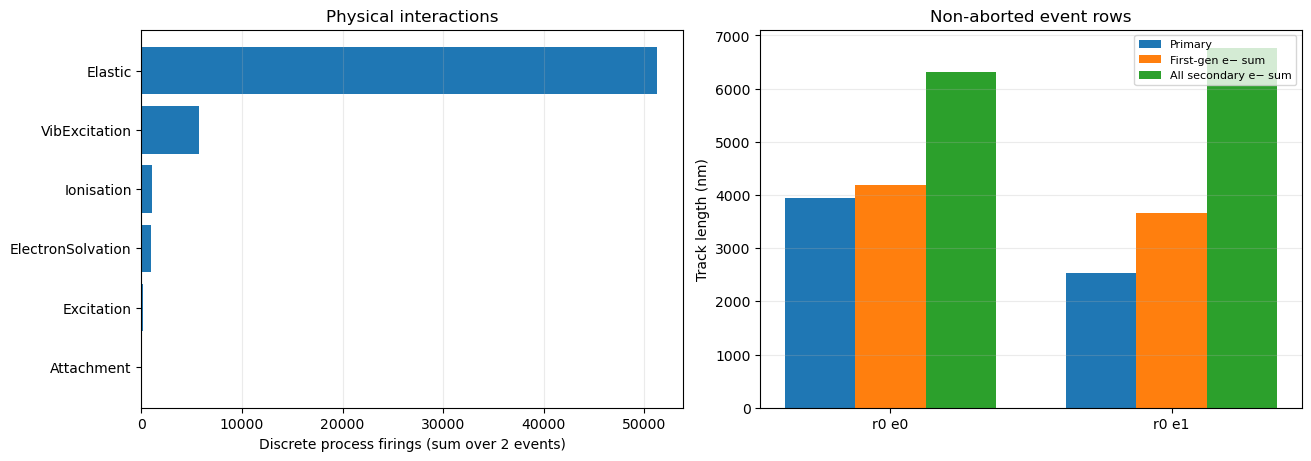

,run,event,primaryEkin0_keV,primaryEkinEnd_keV,primaryEnd,nSecondaryFirstGen,nSecondaryAll
0,0,0,10.0,0.000025,stopped,226,511
1,0,1,10.0,0.000025,stopped,203,503


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
physical_plot = physical_interactions.sort_values('count')
axes[0].barh(physical_plot['label'].str.replace('e-_G4DNA', '', regex=False), physical_plot['count'])
axes[0].set(xlabel=f'Discrete process firings (sum over {events} events)', title='Physical interactions')
axes[0].grid(axis='x', alpha=.25)

event_labels = track_lengths.apply(lambda row: f"r{int(row['run'])} e{int(row['event'])}", axis=1)
x = np.arange(len(track_lengths))
width = .25
axes[1].bar(x - width, track_lengths['primaryLength_nm'], width, label='Primary')
axes[1].bar(x, track_lengths['secondaryFirstGen_nm'], width, label='First-gen e− sum')
axes[1].bar(x + width, track_lengths['secondaryAll_nm'], width, label='All secondary e− sum')
axes[1].set(xticks=x, xticklabels=event_labels, ylabel='Track length (nm)',
            title='Non-aborted event rows')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)
display(track_lengths[['run', 'event', 'primaryEkin0_keV', 'primaryEkinEnd_keV', 'primaryEnd',
                       'nSecondaryFirstGen', 'nSecondaryAll']])

## 6. Pre-chemical water modifications and solvated-electron positions

Geant4's `ElectronicModification` enum encodes `0 = ionized`, `1 = excited`, `2 = dissociative attachment`; the digit after `:` is the water electronic level used by the writer. `e_aq` uses `-1`. The water bars are **record counts in two event files**, grouped by recorded modification, not chemistry species yields. The electron view shows **individual final x–z positions in nm** when present; it is a point projection of pre-chemical records, not a mesoscopic concentration or spatial map. Two events cannot establish spatial statistics.

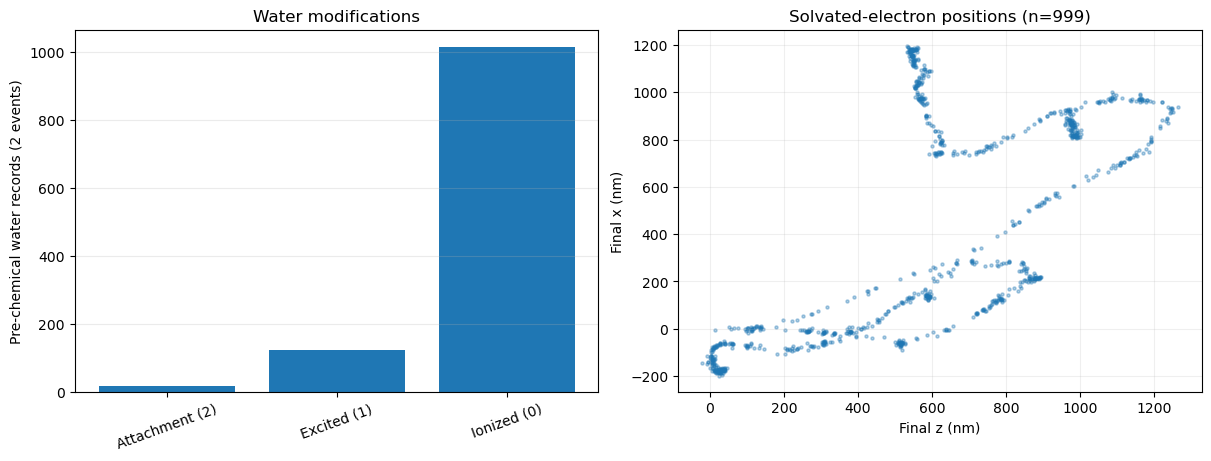

,modification,records
0,Attachment (2),17
1,Excited (1),122
2,Ionized (0),1014


In [8]:
water = prechemical_records.loc[prechemical_records['molecule'] == 'H2O'].copy()
water['modification'] = water['electron_modification'].astype(str).str.split(':').str[0].map({
    '0': 'Ionized (0)', '1': 'Excited (1)', '2': 'Attachment (2)'})
assert water['modification'].notna().all()
water_counts = water['modification'].value_counts().sort_index()
electron_positions = prechemical_records.loc[prechemical_records['molecule'] == 'e_aq'].dropna(
    subset=['x_nm', 'y_nm', 'z_nm'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].bar(water_counts.index, water_counts.values)
axes[0].tick_params(axis='x', rotation=20)
axes[0].set(ylabel=f'Pre-chemical water records ({events} events)', title='Water modifications')
axes[0].grid(axis='y', alpha=.25)
if not electron_positions.empty:
    axes[1].scatter(electron_positions['z_nm'], electron_positions['x_nm'], s=5, alpha=.35)
    axes[1].set(xlabel='Final z (nm)', ylabel='Final x (nm)',
                title=f'Solvated-electron positions (n={len(electron_positions)})')
    axes[1].grid(alpha=.2)
else:
    axes[1].text(.5, .5, 'No final e_aq positions in these files', ha='center', va='center',
                 transform=axes[1].transAxes)
    axes[1].set(title='Solvated-electron positions')
display(fig)
plt.close(fig)
display(pd.DataFrame({'modification': water_counts.index, 'records': water_counts.values}))

## 7. Particle-stage species and recorded reactions

The plots below use **`IRT_DUMP`, with the mesoscopic stage disabled in the default data**, so its particle-stage species records extend to just under **1 µs (1000 ns)**. The separate `MESO_DUMP` hands over at **5 ns** in the default run: its particle scoring stops there, and its later counts appear in the next section on their own record grid. These are two different seeded simulations; the plots do not imply continuity between them.

Mean count is summed `number / nEvent`; mean event G is `sumG / nEvent` in molecules per 100 eV. The plotted G values use that event-wise definition, separately from G4Utils' aggregate-energy `G` column. `Reactions_nt_reactions.csv` counts **particle-stage bimolecular firings only**; bulk acid-base/scavenger channels that bypass this hook, and mesoscopic reactions, are absent. Time labels are upper edges of bins in ns, with overflow folded into the last edge. The default two-event plots demonstrate the workflow.


**Selected IRT input:** 2 events; mesoscopic stage enabled: False; configured chemistry end 1000 ns. Actual species records: 0.001–999.999 ns.

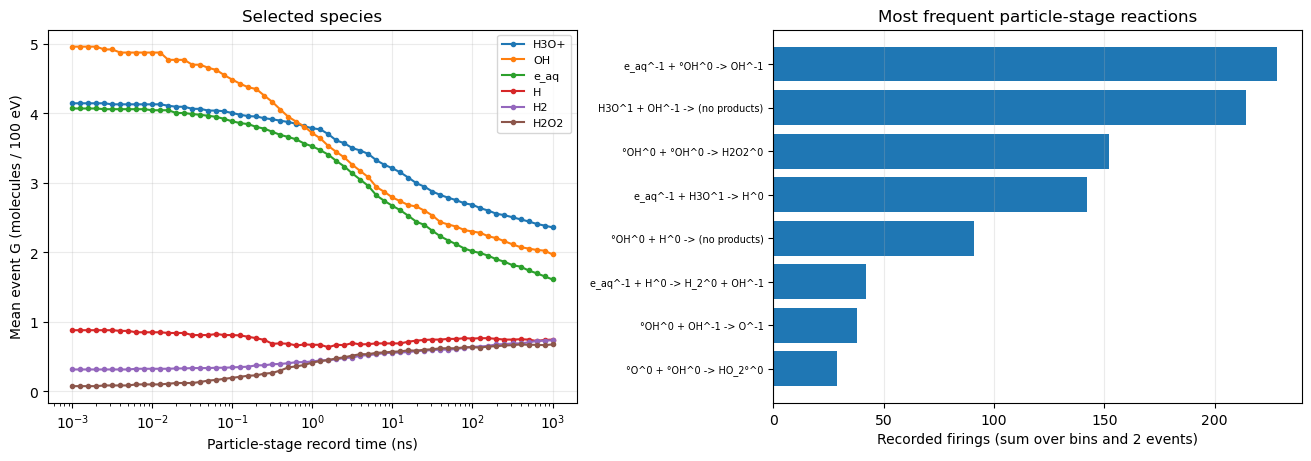

,species,time_ns,number,nEvent,mean_count_per_event,sumG,mean_event_G_per_100eV,G
791,H3O+,999.999,472,2,236.0,4.72,2.360,2.360
782,OH,999.999,394,2,197.0,3.94,1.970,1.970
787,e_aq,999.999,322,2,161.0,3.22,1.610,1.610
780,H,999.999,149,2,74.5,1.49,0.745,0.745
786,H2,999.999,147,2,73.5,1.47,0.735,0.735
788,H2O2,999.999,135,2,67.5,1.35,0.675,0.675
783,OH-,999.999,119,2,59.5,1.19,0.595,0.595
785,O,999.999,13,2,6.5,0.13,0.065,0.065


,reactionId,reaction,count,upper_edge_ns
0,3,H3O^1 + OH^-1 -> (no products),3,0.001
1,7,H^0 + H^0 -> H_2^0,1,0.001
2,11,e_aq^-1 + H3O^1 -> H^0,2,0.001
3,14,e_aq^-1 + H^0 -> H_2^0 + OH^-1,1,0.001
4,19,e_aq^-1 + °OH^0 -> OH^-1,3,0.001
5,25,°OH^0 + °OH^0 -> H2O2^0,8,0.001
6,26,°O^0 + °OH^0 -> HO_2°^0,5,0.001
7,3,H3O^1 + OH^-1 -> (no products),3,0.010


In [9]:
display(Markdown(
    f'**Selected IRT input:** {events} events; mesoscopic stage enabled: '
    f"{irt_dump.manifest.raw.get('mesoEnabled')}; configured chemistry end "
    f'{irt_dump.manifest.chemistryEndTime_ns:g} ns. '
    f'Actual species records: {particle_species.time_s.min() * 1e9:g}–'
    f'{particle_species.time_s.max() * 1e9:g} ns.'
))
species_view = particle_species.copy()
species_view['time_ns'] = species_view['time_s'] * 1e9
species_view['mean_count_per_event'] = species_view['number'] / species_view['nEvent']
species_view['mean_event_G_per_100eV'] = species_view['sumG'] / species_view['nEvent']
last_time = species_view['time_ns'].max()
selected_species = (species_view.loc[species_view['time_ns'] == last_time]
                    .nlargest(6, 'mean_count_per_event')['species'].tolist())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for name in selected_species:
    series = species_view.loc[species_view['species'] == name].sort_values('time_ns')
    axes[0].plot(series['time_ns'], series['mean_event_G_per_100eV'], marker='.', label=name)
axes[0].set(xlabel='Particle-stage record time (ns)',
            ylabel='Mean event G (molecules / 100 eV)', title='Selected species')
axes[0].set_xscale('log')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=.25)

reaction_totals = particle_reactions.groupby('reaction', as_index=False)['count'].sum().nlargest(8, 'count')
axes[1].barh(reaction_totals['reaction'].iloc[::-1], reaction_totals['count'].iloc[::-1])
axes[1].set(xlabel=f'Recorded firings (sum over bins and {events} events)',
            title='Most frequent particle-stage reactions')
axes[1].tick_params(axis='y', labelsize=7)
axes[1].grid(axis='x', alpha=.25)
display(fig)
plt.close(fig)
display(species_view.loc[species_view['time_ns'] == last_time,
                         ['species', 'time_ns', 'number', 'nEvent', 'mean_count_per_event',
                          'sumG', 'mean_event_G_per_100eV', 'G']]
        .sort_values('mean_count_per_event', ascending=False).head(8))
display(particle_reactions[['reactionId', 'reaction', 'time_s', 'count']].head(8)
        .assign(upper_edge_ns=lambda frame: frame['time_s'] * 1e9)
        .drop(columns='time_s'))

## 8. Mesoscopic aggregate counts and spatial-file metadata

`SpeciesMeso.csv` contains **summed species counts across two events** on the mesoscopic log record grid from the **5 ns hand-over** to the configured end time. Divide by manifest `totalEvents` for the mean count per event shown below. The TXT file already contains means; dividing it again would be wrong. These curves do not report particle-stage reaction types, and the optional HDF5 output is shown as file metadata only. A missing or empty aggregate CSV skips the curve with regeneration guidance. Two events are a workflow check, not a converged chemical yield.

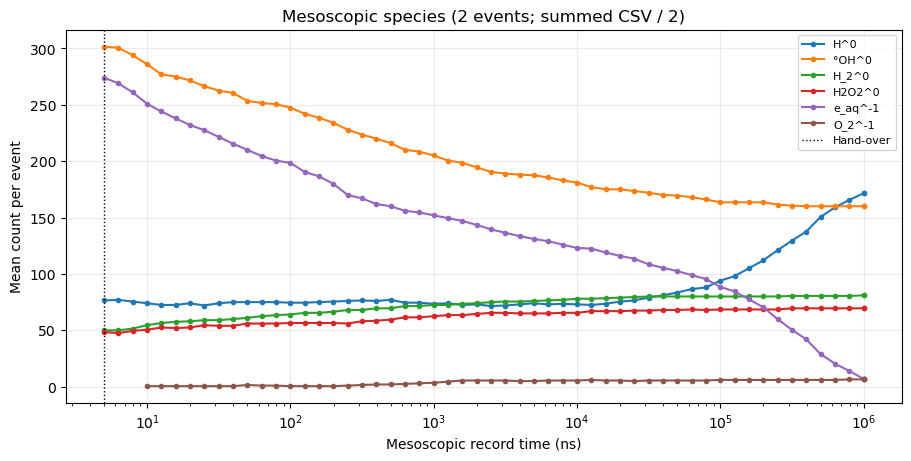

,time_ns,species,count,mean_count_per_event
0,5.0,H2O2^0,97,48.5
1,5.0,H3O^1,643,321.5
2,5.0,HO_2^-1,3,1.5
3,5.0,HO_2°^0,13,6.5
4,5.0,H^0,153,76.5
5,5.0,H_2^0,100,50.0
6,5.0,OH^-1,83,41.5
7,5.0,O^-1,11,5.5
8,5.0,O_2^0,4,2.0
9,5.0,e_aq^-1,548,274.0


**Spatial-file metadata only** (no mesh snapshots or concentration map):

,run,event,snapshots,first_time_ns,last_time_ns,first_cell_size_nm
0,0,0,55,5.0,1000000.0,15.258789
1,0,1,55,5.0,1000000.0,15.258789


In [10]:
if meso_species.empty:
    display(Markdown('**No mesoscopic aggregate counts to plot.** Enable `/chem/meso/enable true` with IRT_syn and regenerate `SpeciesMeso.csv`; the spatial file alone does not provide an aggregate count curve.'))
else:
    meso_view = meso_species.copy()
    meso_view['mean_count_per_event'] = meso_view['count'] / meso_dump.manifest.totalEvents
    last_meso_time = meso_view['time_ns'].max()
    selected_meso = (meso_view.loc[meso_view['time_ns'] == last_meso_time]
                     .nlargest(6, 'mean_count_per_event')['species'].tolist())
    fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
    for name in selected_meso:
        series = meso_view.loc[meso_view['species'] == name].sort_values('time_ns')
        ax.plot(series['time_ns'], series['mean_count_per_event'], marker='.', label=name)
    ax.axvline(meso_dump.manifest.handOverTime_ns, color='black', linestyle=':',
               linewidth=1, label='Hand-over')
    ax.set_xscale('log')
    ax.set(xlabel='Mesoscopic record time (ns)', ylabel='Mean count per event',
           title=f'Mesoscopic species ({meso_events} events; summed CSV / {meso_events})')
    ax.legend(fontsize=8)
    ax.grid(alpha=.25)
    display(fig)
    plt.close(fig)
    display(meso_view.loc[meso_view['time_ns'] == meso_view['time_ns'].min(),
                           ['time_ns', 'species', 'count', 'mean_count_per_event']].head(10))

if spatial_file is not None:
    display(Markdown('**Spatial-file metadata only** (no mesh snapshots or concentration map):'))
    display(meso_spatial_metadata)
else:
    display(Markdown('Spatial HDF5 file unavailable; set `/chem/meso/spatialOutput true` before `/run/initialize` to inspect metadata.'))